# Homework 8.2 - Part V

## Generative AI Interpretation

The central analogy is

$$
true\ state
\longrightarrow
distorted\ observation
\longrightarrow
learned\ model.
$$

In this toy problem,

$$
X_t
$$

is the true state and

$$
Y_t=X_t-L_t
$$

is the observed distorted state.

A learning system trained only on $Y$ sees the distribution of $Y$, not the hidden distribution of $X$.

## What systematic distortion can do

A generative model can fit its training distribution extremely well and still misrepresent the hidden world if the training observations are systematically distorted.

Possible analogues include:

- selection bias;
- reporting bias;
- measurement error;
- compression;
- filtering;
- preference labels;
- institutional incentives;
- missing observations.

This is not necessarily an optimization failure.

The learned model may faithfully reproduce the biased distribution it was given.

## Can a model recover the truth?

Not automatically.

If the observation mechanism is unknown and several hidden processes are compatible with the same observed law, the hidden truth cannot be identified from the observed data alone.

However, Part IV shows that it is also too strong to claim that hidden states are always unrecoverable.

If the distortion mechanism, parameters, initial distortion, and full exact observation path are known, the hidden state can be uniquely reconstructed in this model.

Recoverability therefore depends on the information structure and the observation model.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wasserstein_distance

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_2"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_2"

config = json.loads(
    (
        DATA_DIR
        / "hw8_2_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

A = float(
    config["a"]
)

KAPPA = float(
    config["kappa"]
)

SIGMA = float(
    config["sigma"]
)

ETA = float(
    config["eta"]
)

X0 = float(
    config["x0"]
)

L0 = float(
    config["l0"]
)

DT = 0.01
T = 20.0
N_PATHS = 20000
SEED = 63851

## Numerical illustration of observation distortion

The next simulation compares the cross-sectional distribution of the hidden truth $X_T$ with the observed variable $Y_T$.

This is not a machine-learning benchmark.

It is a direct numerical illustration that the observation process can shift the distribution seen by a learner.

In [2]:
rng = np.random.default_rng(
    SEED
)

x = np.full(
    N_PATHS,
    X0,
    dtype=float,
)

l = np.full(
    N_PATHS,
    L0,
    dtype=float,
)

n_steps = int(
    round(
        T / DT
    )
)

for _ in range(
    n_steps
):
    z = rng.normal(
        size=N_PATHS
    )

    x_old = x.copy()
    l_old = l.copy()

    x = (
        x_old
        + A
        * (
            -x_old
            + l_old
        )
        * DT
        + SIGMA
        * np.sqrt(
            DT
        )
        * z
    )

    l = (
        l_old
        - KAPPA
        * np.abs(
            x_old
        )
        / (
            1.0
            + ETA
            * np.abs(
                l_old
            )
        )
        * DT
    )


y = (
    x
    - l
)

metrics = {
    "T": T,
    "n_paths": N_PATHS,
    "mean_X": float(
        np.mean(
            x
        )
    ),
    "mean_Y": float(
        np.mean(
            y
        )
    ),
    "mean_L": float(
        np.mean(
            l
        )
    ),
    "std_X": float(
        np.std(
            x,
            ddof=1,
        )
    ),
    "std_Y": float(
        np.std(
            y,
            ddof=1,
        )
    ),
    "mean_absolute_observation_distortion": float(
        np.mean(
            np.abs(
                y - x
            )
        )
    ),
    "correlation_X_Y": float(
        np.corrcoef(
            x,
            y
        )[0, 1]
    ),
    "wasserstein_X_vs_Y": float(
        wasserstein_distance(
            x,
            y,
        )
    ),
}

(
    DATA_DIR
    / "part5_observation_distortion_metrics.json"
).write_text(
    json.dumps(
        metrics,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        metrics,
        indent=2,
    )
)

{
  "T": 20.0,
  "n_paths": 20000,
  "mean_X": -0.19720411240015479,
  "mean_Y": 0.018159998771402418,
  "mean_L": -0.2153641111715572,
  "std_X": 0.2072581377107756,
  "std_Y": 0.1937841222995322,
  "mean_absolute_observation_distortion": 0.2153641111715572,
  "correlation_X_Y": 0.9762368341683869,
  "wasserstein_X_vs_Y": 0.21536411117155718
}


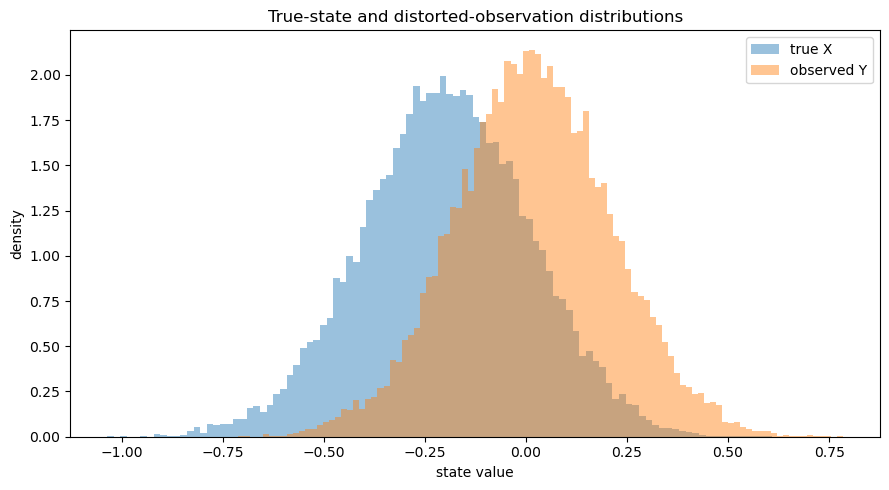

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.2\result images\hw8_2\part5_true_vs_observed_distribution.png


In [3]:
plt.figure(
    figsize=(9, 5)
)

plt.hist(
    x,
    bins=100,
    density=True,
    alpha=0.45,
    label="true X",
)

plt.hist(
    y,
    bins=100,
    density=True,
    alpha=0.45,
    label="observed Y",
)

plt.xlabel(
    "state value"
)
plt.ylabel(
    "density"
)
plt.title(
    "True-state and distorted-observation distributions"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "part5_true_vs_observed_distribution.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    path.resolve(),
)

# Part V Conclusion

The observed distribution can differ materially from the hidden true distribution even when the observation is generated deterministically from the hidden state and distortion process.

A generative model trained only on distorted observations therefore learns the observed data-generating distribution unless additional information allows the distortion to be modeled or inverted.

The correct conclusion is conditional:

- systematic bias can prevent recovery of the hidden truth;
- known dynamics and sufficiently informative observations can sometimes make reconstruction possible.